# 모듈 2 · NLP 미니프로젝트 — BERT 기반 한국어 의미 검색 시스템 개발 및 성능 비교

**기간:** 2일·총 16교시 · **체크포인트:** Day 1 `CP-01~06`, Day 2 `CP-07~10`  
**검색 모델:** TF-IDF · `klue/bert-base` · 한국어 Sentence-BERT  
**최종 결과물:** `search_docs()` + 검색 성능 보고서 + 기술적 의사결정 기록(ADR)

> 이 프로젝트는 GPT로 답변을 생성하거나 BERT를 재학습하는 프로젝트가 아닙니다. **문서의 표현 → 유사도 계산 → Top-k 검색 → 정답 평가 → 오류 분석 → 최종 검색 방식 선정**을 직접 개발합니다.
>
> **학생용 안내:** `[학생 구현]` 셀의 `TODO`를 작성하고 `raise NotImplementedError(...)`를 지운 뒤 `[공통 검증]` 셀을 실행하세요. `[기록]`으로 표시된 Markdown 셀은 실제 결과를 보고 직접 작성합니다. `생각해 볼 질문`은 별도 제출이 아닙니다.


## 00. 환경 설치와 세션 초기화 복구

GPU 세션이 초기화되더라도 첫 코드 셀부터 다시 실행할 수 있도록 구성했습니다. 패키지·모델 가중치·데이터가 없는 경우 자동으로 준비하며, 이미 저장된 파일은 재사용합니다.


**환경 설치(공통).** 필요한 Python 패키지를 한 번에 점검하고 누락되거나 호환 범위를 벗어난 패키지만 설치합니다. GPU 이미지에 이미 설치된 CUDA용 PyTorch는 가능한 한 유지하며, 설치 후 CUDA 상태를 확인합니다.


In [4]:
%pip install hf_transfer

Note: you may need to restart the kernel to use updated packages.


c:\Users\jb016\OneDrive\문서\ai-mini-projects\.venv\Scripts\python.exe: No module named pip


In [5]:
# [공통] 00-1 — 필요한 패키지 자동 설치
import sys, subprocess, importlib.metadata as im
from importlib.util import find_spec

# Python 패키지가 GPU 세션 초기화로 사라진 경우에도 첫 셀부터 복구합니다.
# RunPod GPU 이미지의 PyTorch/CUDA 조합은 가능하면 변경하지 않습니다.
requirements = [
    ('torch', 'torch>=2.2', '2.2'),
    ('numpy', 'numpy>=1.24', '1.24'),
    ('pandas', 'pandas>=2.0', '2.0'),
    ('matplotlib', 'matplotlib>=3.7', '3.7'),
    ('sklearn', 'scikit-learn>=1.3', '1.3'),
    ('transformers', 'transformers>=4.46,<5', '4.46'),
    ('datasets', 'datasets>=3.0,<5', '3.0'),
    ('sentence_transformers', 'sentence-transformers>=3.0,<6', '3.0'),
    ('safetensors', 'safetensors>=0.4', '0.4'),
]

# 설치 확인에는 표준 라이브러리만 사용합니다.
to_install = []
for module, spec, min_version in requirements:
    if find_spec(module) is None:
        to_install.append(spec)
    else:
        try:
            package = {'sklearn': 'scikit-learn', 'sentence_transformers': 'sentence-transformers'}.get(module, module)
            version = im.version(package)
            major_minor = tuple(int(x) for x in version.split('.')[:2])
            required = tuple(int(x) for x in min_version.split('.'))
            if major_minor < required or (module in ('transformers','datasets') and int(version.split('.')[0]) >= 5):
                to_install.append(spec)
        except (im.PackageNotFoundError, ValueError):
            to_install.append(spec)

if to_install:
    print('설치/갱신:', ', '.join(to_install))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
else:
    print('필수 패키지가 이미 준비되어 있습니다.')

# 이미 import한 구버전 라이브러리가 변경된 경우에는 커널 재시작 후 다시 실행하세요.
print('Python:', sys.version.split()[0])


설치/갱신: transformers>=4.46,<5, datasets>=3.0,<5, sentence-transformers>=3.0,<6, safetensors>=0.4


CalledProcessError: Command '['c:\\Users\\jb016\\OneDrive\\문서\\ai-mini-projects\\.venv\\Scripts\\python.exe', '-m', 'pip', 'install', '-q', 'transformers>=4.46,<5', 'datasets>=3.0,<5', 'sentence-transformers>=3.0,<6', 'safetensors>=0.4']' returned non-zero exit status 1.

**작업 폴더와 장치 확인(공통).** `/workspace`가 있으면 프로젝트 파일을 그 아래에, 그 외 환경은 현재 작업 폴더 아래에 보관합니다. 모든 파일·폴더는 처음 실행할 때 자동으로 생성되며 추론 결과는 재실행 시 캐시를 재사용합니다.


In [6]:
# [공통] 00-2 — 프로젝트 경로·GPU·캐시 설정
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = (Path('/workspace') if Path('/workspace').is_dir() else Path.cwd()) / 'nlp_bert_mini'
DATA_RAW = ROOT / 'data' / 'raw'
DATA_PROCESSED = ROOT / 'data' / 'processed'
WEIGHTS = ROOT / 'weights'
CACHE = ROOT / 'outputs' / 'cache'
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
REPORTS = ROOT / 'outputs' / 'reports'
DOCS = ROOT / 'docs'
for folder in [DATA_RAW, DATA_PROCESSED, WEIGHTS, CACHE, TABLES, FIGURES, REPORTS, DOCS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ['HF_HOME'] = str(WEIGHTS / 'huggingface')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('실습 루트:', ROOT)
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU가 없어 CPU로 실행합니다. BERT 임베딩 계산은 더 오래 걸릴 수 있습니다.')

# [공통] CP-08의 Sentence-BERT 가중치(pytorch_model.bin)는 PyTorch 버전이 낮으면 읽지 못할 수 있어 미리 확인합니다.
try:
    _torch_major_minor = tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2])
except ValueError:
    _torch_major_minor = None
if _torch_major_minor is not None and _torch_major_minor < (2, 6):
    print('[주의] PyTorch가 2.6 미만입니다. Day 2의 CP-08에서 Sentence-BERT 로딩이 실패할 수 있으니 강사에게 알려 주세요.')


실습 루트: c:\Users\jb016\OneDrive\문서\ai-mini-projects\mini-project-02\code\nlp_bert_mini
PyTorch: 2.15.0+cpu | Device: cpu
GPU가 없어 CPU로 실행합니다. BERT 임베딩 계산은 더 오래 걸릴 수 있습니다.


### 세션 초기화 시 재실행 방법

1. GitHub에는 **작성한 Notebook과 최종 문서**를 저장하세요. 대용량 모델·원본 데이터는 업로드하지 않습니다.
2. 다음 날 Notebook을 내려받아 **00번 환경 셀부터 순서대로 실행**하면 폴더와 다운로드 데이터가 자동으로 준비됩니다.
3. `/workspace`가 영구 볼륨에 연결되어 있으면 캐시를 재사용합니다. 컨테이너가 삭제되는 환경에서는 다운로드와 임베딩 계산이 다시 진행될 수 있습니다.
4. CP-01~09는 Validation 질문만 사용합니다. **Test 질문의 정답은 CP-10에서 처음 열어 최종 평가**합니다.

**저장 위치:** `data/processed/` (문서·질문), `weights/` (모델 캐시), `outputs/cache/` (문서 벡터), `outputs/tables/` (성능표), `outputs/figures/` (그래프), `outputs/reports/` (결정·최종 평가).


# Day 1 — 한국어 문서 검색기 구현

**목표:** 데이터를 탐색하고 TF-IDF 검색기와 BERT 검색기를 직접 구현합니다. Day 1의 함수들은 Day 2 평가·모델 비교에서 그대로 사용합니다.

---
## CP-01. 문서·질문·정답 구조 분석 및 검색 성능 가설 수립

이번 프로젝트는 KLUE-MRC의 질문–문단 데이터를 **검색 문제**로 다시 구성합니다. 원래 KLUE-MRC는 독해/정답 구간 추출 데이터이며, 본 프로젝트는 정답 문단 하나를 연결하는 별도 검색 평가 데이터이므로 공식 KLUE-MRC 점수와 다릅니다.


**KLUE-MRC 자동 데이터 준비(공통).** 공개 데이터에서 답이 존재하는 질문과 중복되지 않는 문단을 선별해 문단 200개, Validation 질문 60개, 보류 Test 질문 20개를 만듭니다. 질문과 문단은 문서 ID로 연결되며, Test 정답은 CP-10 이전에는 열지 않습니다.


In [7]:
# [공통] CP-01 — 검색용 Corpus / Validation / 보류 Test 자동 준비
from datasets import load_dataset

CORPUS_FILE = DATA_PROCESSED / 'corpus_200.csv'
VALID_FILE = DATA_PROCESSED / 'questions_validation_60.csv'
TEST_FILE = DATA_PROCESSED / 'questions_test_20.csv'
META_FILE = DATA_PROCESSED / 'dataset_meta.json'

# KLUE-MRC 공식 Hugging Face 데이터셋 (validation split만 사용)
# 기존 데이터가 저장되어 있으면 다시 다운로드·선별하지 않습니다.
if not all(f.is_file() for f in (CORPUS_FILE, VALID_FILE, TEST_FILE, META_FILE)):
    raw = load_dataset('klue/klue', 'mrc', split='validation', cache_dir=str(DATA_RAW))
    eligible = []
    seen_contexts = set()
    seen_questions = set()
    for r in raw:
        if bool(r['is_impossible']):
            continue
        context, question = str(r['context']).strip(), str(r['question']).strip()
        if len(context) < 150 or not question or context in seen_contexts or question in seen_questions:
            continue
        answers = r['answers']
        answer_texts = answers.get('text', []) if isinstance(answers, dict) else []
        answer_starts = answers.get('answer_start', []) if isinstance(answers, dict) else []
        if not answer_texts:
            continue
        answer_text = str(answer_texts[0]).strip()
        if not answer_text or answer_text not in context:
            continue
        # ### 답변이 포함된 500자 이내의 문단으로 줄입니다.
        # ### (토큰 수가 MAX_LENGTH를 넘는 문단은 BERT에 넣을 때 뒷부분이 잘릴 수 있습니다.)
        answer_pos = context.find(answer_text)
        left = max(0, min(answer_pos - 180, max(0, len(context) - 500)))
        snippet = context[left:left + 500].strip()
        if answer_text not in snippet:
            continue
        eligible.append({'title': str(r.get('title', '')), 'text': snippet,
                         'question': question, 'guid': str(r['guid'])})
        seen_contexts.add(context)
        seen_questions.add(question)

    assert len(eligible) >= 200, f'선별 가능한 문단이 200개보다 적습니다: {len(eligible)}'
    rng = np.random.default_rng(SEED)
    selected = [eligible[i] for i in rng.choice(len(eligible), size=200, replace=False)]
    docs = [{'doc_id': f'D{i:03d}', 'title': r['title'], 'text': r['text']}
            for i, r in enumerate(selected)]
    corpus_out = pd.DataFrame(docs)
    candidate_idx = rng.permutation(200)[:80]
    qrows = [{'question': selected[int(idx)]['question'],
              'relevant_doc_id': f'D{int(idx):03d}'} for idx in candidate_idx]
    validation_out = pd.DataFrame([
        {'query_id': f'QV{i+1:03d}', **row} for i, row in enumerate(qrows[:60])])
    test_out = pd.DataFrame([
        {'query_id': f'QT{i+1:03d}', **row} for i, row in enumerate(qrows[60:])])

    corpus_out.to_csv(CORPUS_FILE, index=False, encoding='utf-8-sig')
    validation_out.to_csv(VALID_FILE, index=False, encoding='utf-8-sig')
    test_out.to_csv(TEST_FILE, index=False, encoding='utf-8-sig')
    META_FILE.write_text(json.dumps({
        'source': 'klue/klue · mrc · validation', 'seed': SEED,
        'num_documents': 200, 'num_validation_queries': 60, 'num_test_queries': 20,
        'sampling': 'unique contexts; one labeled relevant snippet per question',
        'notes': '수업용 단일 정답 문단 검색 세트. KLUE-MRC의 공식 검색 벤치마크가 아님.'
    }, ensure_ascii=False, indent=2), encoding='utf-8')
    print('KLUE-MRC 데이터로 검색용 소규모 데이터셋을 새로 생성했습니다.')
else:
    print('저장된 프로젝트 데이터셋을 재사용합니다.')

corpus_df = pd.read_csv(CORPUS_FILE, dtype={'doc_id': str}).fillna('')
valid_df = pd.read_csv(VALID_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(corpus_df) == 200 and len(valid_df) == 60
assert valid_df['relevant_doc_id'].isin(corpus_df['doc_id']).all()
assert corpus_df['doc_id'].is_unique
print('문서:', len(corpus_df), '| Validation 질문:', len(valid_df), '| 별도 보류 Test: 20문항')
display(corpus_df[['doc_id', 'title', 'text']].head(3))
display(valid_df.head(3))


ModuleNotFoundError: No module named 'datasets'

**데이터 탐색·시각화(학생 구현).** 질문과 문단의 글자 수를 계산하고 길이 분포를 그림으로 정리합니다. 관찰 결과를 바탕으로 TF-IDF와 BERT가 각각 어떤 질문에서 유리할지 예상하고 CP-09에서 다시 확인합니다.


In [8]:
# [학생 구현] CP-01 — 데이터 길이 분석 및 시각화
corpus_stats = corpus_df.copy()
valid_stats = valid_df.copy()
# TODO 1-1. corpus_stats['char_length']에 문서 text의 글자 수를 계산해 넣으세요.
corpus_stats['char_length'] = corpus_stats['text'].str.len()
# TODO 1-2. valid_stats['char_length']에 질문 question의 글자 수를 계산해 넣으세요.
valid_stats['char_length'] = valid_stats['question'].str.len()
# TODO 1-3. describe()로 문서·질문 길이 통계를 출력하세요.
print('문서 길이 통계:')
display(corpus_stats['char_length'].describe().to_frame('문서 글자 수'))
print('질문 길이 통계:')
display(valid_stats['char_length'].describe().to_frame('질문 글자 수'))
# TODO 1-4. 두 길이 분포를 histogram으로 시각화하고 FIGURES에 저장하세요.
# matplotlib의 plt.subplots(), ax.hist(), fig.savefig()를 사용합니다.
fig, ax = plt.subplots()
ax.hist(corpus_stats['char_length'])
fig.savefig(FIGURES / 'corpus_length.png')

fig, ax = plt.subplots()
ax.hist(valid_stats['char_length'])
fig.savefig(FIGURES / 'valid_length.png')

NameError: name 'corpus_df' is not defined

**질문–정답 문단 겹침 분석(공통).** TF-IDF는 질문과 문단에 같은 글자 묶음이 많이 나올수록 유리합니다. 질문의 글자 2개 묶음(2-gram) 가운데 정답 문단에도 나오는 비율을 질문마다 계산해 `valid_overlap`에 저장합니다. 겹침 비율이 낮은 질문은 문단과 다른 표현으로 물어본 질문입니다. 코드는 제공되며, 학생들은 표를 읽고 아래 기록을 작성합니다. 이 표는 CP-09에서 검색에 실패한 질문과 다시 비교합니다.

In [2]:
# [공통] CP-01 — 질문과 정답 문단의 글자 겹침 비율 (Validation 질문만 사용)

def char_bigrams(text):
    """어절 안에서 만든 글자 2개 묶음의 집합. 예: '검색 성능' → {'검색', '성능'}"""
    return {word[i:i + 2] for word in str(text).split() for i in range(len(word) - 1)}


def overlap_ratio(question, document):
    """질문의 글자 2-gram 중 문단에도 등장하는 비율(0~1)."""
    question_grams = char_bigrams(question)
    if not question_grams:
        return 0.0
    return len(question_grams & char_bigrams(document)) / len(question_grams)


_doc_text = corpus_df.set_index('doc_id')['text']
valid_overlap = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
valid_overlap['overlap'] = [overlap_ratio(q, _doc_text[d])
                            for q, d in zip(valid_overlap['question'], valid_overlap['relevant_doc_id'])]
print('질문–정답 문단 겹침 비율 통계:')
display(valid_overlap['overlap'].describe().to_frame('겹침 비율').round(3))
print('겹침 비율이 가장 낮은 질문 5개:')
display(valid_overlap.sort_values('overlap').head(5)[['query_id', 'question', 'overlap']].round(3))
valid_overlap.to_csv(TABLES / 'cp01_validation_overlap.csv', index=False, encoding='utf-8-sig')

NameError: name 'corpus_df' is not defined

**[기록] 결과 해석 — CP-01**

- 문서 길이와 질문 길이 분포에서 관찰한 특징: **문서 길이는 비교적 일정한 편이고, 질문 길이는 상대적으로 다양하게 나타난다.**
- 질문–정답 문단 겹침 비율 분포에서 관찰한 특징: **전체 질문의 75% 지점에서 겹침 비율은 약 60.1%로 나타나 질문마다 정답 문단과 겹치는 단어의 비율에 차이가 있음을 알 수 있다.**
- 가설 1 — TF-IDF가 잘 찾을 것으로 예상하는 질문과 이유: **질문과 정답 문단의 겹침 비중이 높은 질문은 TF-IDF가 검색에서 유리할 것으로 예상한다. TF-IDF는 질문과 문서에 공통으로 등장하는 단어의 중요도로 유사도를 계산하기 때문에 핵심 단어가 많이 겹칠수록 정답 문단을 찾기 쉬울 것으로 생각한다.**
- 가설 2 — BERT 기반 검색에서 유리하거나 불리할 것 같은 질문과 이유: **BERT 기반 검색은 질문과 정답 문단의 단어가 정확히 일치하지 않더라도 문맥과 유사성을 파악할 수 있어 표현이 다른 질문에서 유리할 것으로 예상한다. 반면 문맥이 부족하거나 세부적인 단어 및 사실 관계를 구분해야 하는 질문에서는 불리할 수 있다고 생각한다.**

**[CP-01 완료 기준]** 문서·질문 길이 통계와 그래프를 만들고 겹침 비율 표를 확인한 뒤, 두 검색 방식의 예상 강점·한계를 기록합니다. **Test 질문은 열지 않습니다.**


---
## CP-02. TF-IDF 기반 기준 검색기 구현

TF-IDF는 이미 배운 전통적인 텍스트 표현 방법입니다. 이번에는 한국어 띄어쓰기의 영향을 줄이기 위해 **문자 2~3-gram TF-IDF**를 기준선으로 사용하고, 질문과 문단 간 유사도로 Top-k를 찾습니다.


**TF-IDF 검색기(학생 구현).** 문서 전체의 벡터를 만든 뒤 질문을 같은 TF-IDF 기준으로 변환합니다. 코사인 유사도에 따라 점수를 정렬하고, 앞에서부터 k개의 문서를 반환합니다.


In [7]:
# [학생 구현] CP-02 — TF-IDF + 공통 Top-k 정렬 함수
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
# TODO 2-1. analyzer='char', ngram_range=(2, 3), max_features=30000인 TfidfVectorizer를
#           tfidf_vectorizer라는 이름으로 만드세요.
tfidf_vectorizer = TfidfVectorizer(analyzer='char', 
                    ngram_range=(2, 3), 
                    max_features=30000
                    )
# TODO 2-2. Corpus의 text로 fit_transform()하여 tfidf_docs를 만드세요.
tfidf_docs = tfidf_vectorizer.fit_transform(corpus_df['text'])

def top_k_results(scores, frame, k=5):
    """점수가 높은 문서 k개를 반환합니다. 키: rank, doc_id, score, text"""
    scores = np.asarray(scores, dtype=np.float64).ravel()
    assert len(scores) == len(frame)
    k = min(max(1, int(k)), len(frame))
    # TODO 2-3. np.argsort(-scores)로 점수 내림차순 상위 k개 인덱스를 고르세요.
    indices = np.argsort(-scores)[:k]
    # TODO 2-4. 위 인덱스로 rank, doc_id, score, text 키를 이 순서대로 가진 딕셔너리 리스트를 반환하세요.
    #           rank는 1부터 시작합니다. 검증 셀이 키의 순서까지 확인합니다.
    results = []
    for rank, idx in enumerate(indices, start=1):
        results.append({
            'rank': rank,
            'doc_id': frame.iloc[idx]['doc_id'],
            'score': float(scores[idx]),
            'text': frame.iloc[idx]['text']
        })

    return results     

def search_tfidf(query, k=5):
    # TODO 2-5. tfidf_vectorizer.transform()으로 질문을 벡터로 만드세요.
    query_vec = tfidf_vectorizer.transform([query])
    # TODO 2-6. cosine_similarity()로 전체 문서와의 점수를 계산하세요.
    scores = cosine_similarity(query_vec, tfidf_docs).ravel()
    # TODO 2-7. top_k_results()를 호출해 검색 결과를 반환하세요.
    return top_k_results(scores, corpus_df, k)

# TODO 2-8. Validation 질문 하나로 상위 3개 문서를 출력해 보세요.
query = valid_df['question'].iloc[0]
results = search_tfidf(query, k=3)

for result in results:
    print(result)

{'rank': 1, 'doc_id': 'D015', 'score': 0.1418197600010136, 'text': '그것이 표준이다. 다른 장면 세트와 마찬가지로, 그림, 아이보리 미니어처 조각, 재판 드라마, 음악 등 매체마다 묘사가 갖는 실제적인 함의는 매체별로 다른 관습으로 이어졌고, 지리학이나 종교 질서의 영향도 다양했다. 성모 칠고와 일치하는 세트가 있다; 두 세트 모두 성모의 삶을 묘사하는 장면의 선택에 영향을 주었다.\n\n원래 성모칠락은 다섯 가지였다. 나중에 그 숫자는 중세 문학에서 7개가 가장 흔한 숫자로 남아 있었지만, 그 수는 7개, 9개, 심지어 15개로 늘어났다. 다른 것들은 예술에서 거의 찾아볼 수 없다. 마리아의 다섯 가지 기쁨은 가웨인의 힘의 원천으로 14세기 시 가웨인 경과 녹기사에 언급되어 있다. 그 헌신은 특히 종교 개혁 이전의 영국에서 인기가 있었다. 프랑스 작가 앙투안 드 라 세일은 1462년경 레 퀸제 조이스 데 마리아게("결혼의 15가지 기쁨")라는 풍자를 완성했는데, 이 풍자는 유명한 리타니인 레스 퀸제 조이스 데 노트르담의 형식을 부분적으로 패러디했다.'}
{'rank': 2, 'doc_id': 'D078', 'score': 0.06973130471199306, 'text': '산업 혁명\n 산업혁명은 단순한 생산기술의 혁신에 의해서 발생한 생산성의 비약적 증대가 아니라 공장제 수공업(매뉴팩처)에서 기계제 대공장(팩토리)을 출현시켜 자본주의적 생산관계를 확립한 진정한 변혁이다. 이 생산상의 혁명이 최초로 영국에서 실현된 데에는 몇 가지 원인이 있다. 우선 영국에 있어서는 봉건적인 여러 관계가 재빨리 해체되고, 타국에 비해서 유리한 조건으로 상공업의 발전이 있었다는 것, 특히 양모 공업이 국민적 규모로 전개되어 있었다는 것이 지적된다. 나아가 시민혁명을 통해서 자본주의의 발전을 저지하는 등 제도상의 여러 장해가 대체로 제거되었다는 것도 중요한 원인이다. 또한 17, 18세기에 있어서 국내산업의 보호와 적극적인 

**TF-IDF 검색 검증(공통).** 점수가 가장 큰 문서가 첫 번째 결과로 반환되어야 합니다. 검색 함수가 `rank·doc_id·score·text`를 모두 반환해야 BERT 검색과 같은 평가기를 재사용할 수 있습니다.


In [8]:
# [공통 검증] CP-02
_demo_corpus = pd.DataFrame({'doc_id': ['A', 'B', 'C'], 'text': ['가', '나', '다']})
_demo_rank = top_k_results([0.2, 0.9, 0.4], _demo_corpus, 2)
assert [h['doc_id'] for h in _demo_rank] == ['B', 'C']
assert list(_demo_rank[0]) == ['rank', 'doc_id', 'score', 'text']
assert tfidf_docs.shape[0] == len(corpus_df)
_check = search_tfidf(valid_df.iloc[0]['question'], 5)
assert len(_check) == 5 and len(set(h['doc_id'] for h in _check)) == 5
print('CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료')


CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료


**[CP-02 완료 기준]** TF-IDF 문서 행렬을 만들고 `search_tfidf(query, k)`가 유사도 내림차순의 결과를 반환하며 검증 셀을 통과합니다.


---
## CP-03. BERT Encoder 출력과 입력 Shape 분석

기존 KLUE-YNAT 뉴스 분류에서는 BERT 출력으로 분류했습니다. 이번에는 Classification Head가 아닌 **BERT Encoder의 토큰별 문맥 벡터(`last_hidden_state`)**를 문서 표현에 사용합니다.


**BERT 모델 로딩(공통).** `klue/bert-base`를 불러와 추론 모드로 전환합니다. 다운로드된 가중치는 `weights/`에 저장되므로 GPU 세션이 유지되는 동안 반복 다운로드하지 않습니다.


In [9]:
# [공통] CP-03 — BERT Encoder·Tokenizer 준비
from transformers import AutoTokenizer, AutoModel

BASE_MODEL = 'klue/bert-base'
MAX_LENGTH = 256
BATCH_SIZE = 16

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS))
bert_model = AutoModel.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS), use_safetensors=True)
bert_model = bert_model.to(DEVICE).eval()
print('BERT Encoder:', BASE_MODEL, '| hidden_size:', bert_model.config.hidden_size)


tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

BERT Encoder: klue/bert-base | hidden_size: 768


**BERT 입력·출력 구조 확인(학생 구현).** 서로 다른 길이의 질문 두 개를 Batch로 묶고 `attention_mask`와 `last_hidden_state`의 Shape를 확인합니다. 토큰마다 벡터가 하나씩 있으므로 아직 문장 하나당 벡터 하나인 상태가 아님을 확인하세요.


In [10]:
# [학생 구현] CP-03 — 토큰 단위 문맥 벡터 확인
sample_questions = valid_df['question'].head(2).astype(str).tolist()
# TODO 3-1. tokenizer()로 질문 두 개를 padding/truncation하여 return_tensors='pt'로 만들고
#           inputs라는 이름으로 저장하세요.
input = tokenizer(
    sample_questions,
    padding=True, 
    truncation=True,
    return_tensors='pt'
)

# TODO 3-2. 입력 Tensor를 DEVICE로 옮기세요.
inputs = {key: value.to(DEVICE) for key, value in input.items()}

# TODO 3-3. torch.inference_mode() 안에서 bert_model(**inputs)를 실행하세요.
with torch.inference_mode():
    output = bert_model(**inputs)

# TODO 3-4. 출력의 last_hidden_state는 last_hidden, 입력의 attention_mask는 mask라는 이름으로 저장하고
#           두 Tensor의 Shape와 문장별 유효 토큰 수를 출력하세요.
# [주의] 다음 CP-04 셀이 last_hidden과 mask라는 이름을 그대로 사용합니다.
last_hidden = output.last_hidden_state #토큰 벡터
mask = inputs["attention_mask"]

print("Input shape", input["input_ids"].shape)
print("Output shape", last_hidden.shape)
print("Mask shape", mask.shape)


Input shape torch.Size([2, 19])
Output shape torch.Size([2, 19, 768])
Mask shape torch.Size([2, 19])


**[기록] 결과 해석 — CP-03**

- `last_hidden_state`의 세 차원(Batch·Token·Hidden)이 각각 의미하는 것: **Batch는 입력한 문장의 개수 2개, Token은 각 문장을 구성하는 토큰의 개수 19개, Hidden은 각 토큰을 표현하는 특성 벡터의 차원 수 768개를 의미한다.**
- `attention_mask`가 0인 위치를 평균에서 제외해야 하는 이유: **Attention Mask가 0인 위치는 실제 문장이 아닌 패딩으로 만들어진 것이기 때문이다. 패딩까지 평균 계산에 포함하면 실제 문장의 특성을 정확하게 반영하지 못하므로 제외해야 한다.**

**[CP-03 완료 기준]** BERT Encoder 출력 Shape·Attention Mask를 직접 확인하고, 토큰 표현과 문장 표현의 차이를 기록합니다.


---
## CP-04. Attention Mask 기반 Mean Pooling 구현

BERT는 토큰마다 벡터 하나를 출력하지만 검색에서는 **질문 1개·문단 1개를 각각 하나의 벡터**로 표현해야 합니다. 패딩 위치를 제외하고 유효 토큰 벡터만 평균내는 함수를 구현합니다.


**Masked Mean Pooling(학생 구현).** Attention Mask를 `(B, T, 1)`로 바꾸어 토큰별 벡터에 곱합니다. 유효 토큰 벡터의 합을 유효 토큰 수로 나누되, 0으로 나누는 경우는 방지합니다.


In [11]:
# [학생 구현] CP-04 — Masked Mean Pooling

def mean_pooling(last_hidden_state, attention_mask):
    """(B,T,H)+(B,T) → (B,H), 패딩 제외 토큰 평균."""
    # TODO 4-1. 패딩 위치의 벡터가 평균에 들어가지 않도록, attention_mask를 토큰 벡터와 곱할 수 있는
    #           모양 (B,T,1)로 바꾸세요.
    attention_mask = attention_mask.unsqueeze(-1)
    # TODO 4-2. 토큰 벡터에 mask를 적용해 패딩 위치의 벡터를 0으로 만드세요.
    masked_hidden = attention_mask * last_hidden_state
    # TODO 4-3. 토큰 축(T)을 따라 벡터를 합해 문장마다 벡터 하나 (B,H)가 되게 하세요.
    sentence_sum = masked_hidden.sum(dim=1)
    # TODO 4-4. 문장별 유효 토큰 수로 나누어 평균 (B,H)를 반환하세요.
    #           유효 토큰 수가 0인 경우에도 0으로 나누지 않도록 처리합니다.
    valid_count = attention_mask.sum(dim=1)
    sentence_mean = sentence_sum / valid_count.clamp(min=1)
    return sentence_mean

sentence_vecs = mean_pooling(last_hidden, mask)
print('Pooling 후:', tuple(sentence_vecs.shape))


Pooling 후: (2, 768)


**Pooling 숫자 검증(공통).** 마지막 토큰에 매우 큰 숫자가 들어 있어도 `attention_mask=0`이면 평균에 포함되면 안 됩니다. 아래 검증 셀은 실제 BERT 가중치 없이 작은 Tensor만으로 정답을 확인합니다.


In [12]:
# [공통 검증] CP-04 — Padding을 제외한 평균
_toy_hidden = torch.tensor([[[1., 0.], [3., 2.], [100., 100.]],
                            [[2., 4.], [20., 20.], [40., 40.]]])
_toy_mask = torch.tensor([[1, 1, 0], [1, 0, 0]])
_toy_out = mean_pooling(_toy_hidden, _toy_mask)
assert _toy_out.shape == (2, 2)
assert torch.allclose(_toy_out, torch.tensor([[2., 1.], [2., 4.]]), atol=1e-6)
assert sentence_vecs.shape == (2, bert_model.config.hidden_size)
print('CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인')


CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인


**[CP-04 완료 기준]** `mean_pooling()`을 완성하고 유효 토큰만 평균을 낸 검증을 통과합니다. **생각해 볼 질문:** `attention_mask`를 무시하면 문장 길이에 따른 패딩이 검색 결과에 어떤 영향을 줄까요? **'attention_mask'를 무시하고 안 하게 되면 무의미한 값까지 평균 계산에 포함되어 문장 길이에 따라 실제 문장 벡터와 다르게 나올 수 있다. 이로 인해 문장의 의미를 제대로 반영하지 못하고 영향을 줄 수 있다.**

---
## CP-05. BERT 문서 임베딩과 코사인 유사도 계산

문서 200개를 BERT Encoder와 Pooling을 통과시켜 같은 차원의 벡터로 변환합니다. 질문 벡터와 각 문서 벡터의 **코사인 유사도**를 직접 계산합니다.


**BERT 임베딩 Batch 처리(학생 구현).** 문서를 한 번에 모두 처리하면 메모리를 많이 사용하므로 16개씩 Tokenizer → BERT → Mean Pooling을 반복합니다. 결과는 NumPy 배열로 합치며, 이후 GPU를 다시 사용하지 않도록 저장합니다.


In [13]:
# [학생 구현] CP-05 — BERT 임베딩 생성 함수

def encode_bert_texts(texts, batch_size=BATCH_SIZE):
    """문장/문단 리스트 → (N, Hidden) NumPy 배열."""
    texts = [str(t) for t in texts]
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        # TODO 5-1. batch를 tokenizer()로 Tensor로 변환하고 DEVICE로 옮기세요.
        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True, 
            return_tensors='pt',
            )
        inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
        # TODO 5-2. 추론 모드에서 bert_model(**encoded)로 last_hidden_state를 얻으세요.
        with torch.inference_mode(): 
            outputs = bert_model(**inputs).last_hidden_state
        # TODO 5-3. mean_pooling()을 적용하고 CPU NumPy 배열로 vectors에 추가하세요.
        sentence_vecs = mean_pooling(outputs, inputs["attention_mask"])
        sentence_vecs = sentence_vecs.cpu().numpy()
        vectors.append(sentence_vecs)
        
    return np.vstack(vectors) if vectors else np.empty((0, bert_model.config.hidden_size))


def cosine_scores(query_vector, document_matrix):
    """질문 벡터 (H,)와 문서 행렬 (N,H) → 유사도 (N,)."""
    query_vector = np.asarray(query_vector, dtype=np.float64).reshape(-1)
    document_matrix = np.asarray(document_matrix, dtype=np.float64)
    # TODO 5-4. 질문 벡터와 각 문서 벡터의 내적을 구하세요. 결과는 문서 수만큼의 값 (N,)입니다.
    dot = np.dot(document_matrix, query_vector)
    # TODO 5-5. 질문 벡터의 크기(노름)와 각 문서 벡터의 크기를 구하세요.
    document_norms = np.linalg.norm(document_matrix, axis=1) 
    query_norm = np.linalg.norm(query_vector)
    # TODO 5-6. 내적을 두 크기의 곱으로 나눈 코사인 유사도 배열 (N,)을 반환하세요.
    #           분모가 0이 되는 경우에도 오류가 나지 않도록 처리합니다.
    cosine_scores = dot / np.maximum(query_norm * document_norms, 1e-8)
    return cosine_scores


**문서 임베딩 캐싱(공통).** `bert_corpus_200_256.npy`가 이미 있으면 다시 계산하지 않습니다. 다만 저장된 벡터가 **지금의 `encode_bert_texts()`가 계산한 결과와 같은지** 앞 문서 4개로 먼저 확인합니다. 함수를 고친 뒤라서 결과가 다르면 전체를 다시 계산해 덮어쓰므로, 예전에 잘못 계산된 벡터가 계속 쓰이지 않습니다.

In [14]:
# [공통] CP-05 — BERT Corpus 임베딩 생성/재사용
BERT_DOC_CACHE = CACHE / 'bert_corpus_200_256.npy'


def load_or_encode(cache_file, texts, n_check=4):
    """저장된 임베딩이 현재 encode_bert_texts()의 결과와 같을 때만 재사용합니다.

    앞 n_check개를 다시 계산해 저장본과 비교하고, 다르면(함수를 고친 경우 등) 전체를 다시 계산해 덮어씁니다.
    """
    texts = [str(t) for t in texts]
    expected_shape = (len(texts), bert_model.config.hidden_size)
    if cache_file.is_file():
        cached = np.load(cache_file)
        if cached.shape == expected_shape:
            fresh = encode_bert_texts(texts[:n_check])
            if fresh.shape == cached[:n_check].shape and np.allclose(fresh, cached[:n_check], atol=1e-3):
                print('저장된 임베딩 재사용:', cache_file.name)
                return cached
        print('저장된 임베딩이 현재 함수의 결과와 달라 다시 계산합니다:', cache_file.name)
    vectors = encode_bert_texts(texts)
    np.save(cache_file, vectors)
    return vectors


bert_doc_vectors = load_or_encode(BERT_DOC_CACHE, corpus_df['text'].tolist())
print('BERT 문서 벡터 Shape:', bert_doc_vectors.shape)

BERT 문서 벡터 Shape: (200, 768)


**코사인 유사도 검증(공통).** 질문과 같은 방향의 문서 벡터는 유사도가 1에 가까워야 합니다. 문서가 200개이므로 질문 하나에 대한 점수 배열도 반드시 길이 200이어야 합니다.


In [15]:
# [공통 검증] CP-05
_test_scores = cosine_scores(np.array([1., 0.]),
                             np.array([[1., 0.], [0., 1.], [-1., 0.]]))
assert np.allclose(_test_scores, [1., 0., -1.], atol=1e-6)
assert bert_doc_vectors.shape == (200, bert_model.config.hidden_size)
assert np.isfinite(bert_doc_vectors).all()
print('CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상')


CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상


**[CP-05 완료 기준]** BERT 임베딩 (200, 768) 배열을 저장하고, 직접 작성한 `cosine_scores()`가 숫자 검증을 통과합니다.


---
## CP-06. Top-k BERT 문서 검색기 완성

이제 질문을 같은 BERT Encoder로 벡터화하고 저장된 문서 벡터들과 비교합니다. CP-02에서 구현한 `top_k_results()`를 재사용해 **검색기가 하나의 완성된 프로그램**으로 동작하도록 연결합니다.


**BERT 검색 함수(학생 구현).** 질문 하나를 BERT 임베딩으로 변환해 문서 200개와 코사인 유사도를 계산합니다. 상위 k개 결과의 문서 ID, 유사도, 원문을 같은 인터페이스로 반환해야 Day 2에서 두 검색기를 공정하게 평가할 수 있습니다.


In [16]:
# [학생 구현] CP-06 — BERT 검색 함수
bert_query_cache = {}  # Day 2에 일괄 준비할 검색 질문 벡터 캐시

def search_bert(query, k=5):
    query = str(query)
    # TODO 6-1. 캐시에 query가 있다면 재사용하고, 없다면 encode_bert_texts([query])[0]를 사용하세요.
    if query in bert_query_cache:
        query_vector = bert_query_cache[query]
    else: 
        query_vector = encode_bert_texts([query])[0]
        bert_query_cache[query] = query_vector
    # TODO 6-2. cosine_scores()로 corpus 전체 문서와의 점수를 구하세요.
    scores = cosine_scores(query_vector, bert_doc_vectors)
    # TODO 6-3. top_k_results()를 호출하여 상위 k개의 검색 결과를 반환하세요.
    rank = top_k_results(scores, corpus_df, k=k)

    # TODO 6-4. Validation 질문 하나를 골라 BERT 검색 결과 Top-3를 표로 확인하세요.
    # display(pd.DataFrame(rank).head(3)) # CP-07에서 표가 반복 출력되어 주석처리

    return rank

**검색기 출력 검증(공통).** 두 검색 방식이 반환하는 항목과 순위 형식이 동일한지 확인합니다. 단위 테스트는 검색 결과의 구조만 확인하며, 이 단계에서 검색 점수가 높아야 한다는 조건을 요구하지 않습니다.


In [17]:
# [공통 검증] CP-06
_question = valid_df.iloc[0]['question']
for _search_fn in [search_tfidf, search_bert]:
    _hits = _search_fn(_question, 3)
    assert len(_hits) == 3 and [h['rank'] for h in _hits] == [1, 2, 3]
    assert all({'doc_id', 'text', 'score'} <= set(h) for h in _hits)
    assert _hits[0]['score'] >= _hits[1]['score'] >= _hits[2]['score']
print('CP-06 통과: TF-IDF / BERT Top-k 검색기 완성')


CP-06 통과: TF-IDF / BERT Top-k 검색기 완성


**[Day 1 완료 기준]** 문서 분석과 검색 성능 가설, TF-IDF 검색기, BERT Masked Mean Pooling, 코사인 유사도, `search_bert()`와 검증 셀을 모두 완료합니다. **Day 1 종료 후 작성한 Notebook을 GitHub에 저장하세요.**


# Day 2 — 검색 성능 평가·오류 분석·최종 검색 방식 선정

둘째 날은 `CP-07~10`을 진행합니다. **Validation 질문에서만 모델을 비교하고 선택**한 후, 보류 Test 질문은 CP-10의 최종 평가에 사용합니다.

---
## CP-07. 검색 평가 함수 구현 — Hit@1 · Recall@3 · MRR@5

분류에서 Accuracy·F1을 계산했던 것처럼 문서 검색에도 평가 기준이 필요합니다. 이번에는 질문마다 **정답 문서가 하나**이므로, 그 문서가 몇 위에 검색되었는지로 성능을 평가합니다.


**검색 평가 지표 구현(학생 구현).** Hit@1은 정답 문서가 첫 번째인지, Recall@3은 상위 3개에 있는지, MRR@5는 상위 5개 안에서의 정답 순위 역수입니다. 질문별 지표를 평균하여 전체 검색 성능을 계산합니다.


In [18]:
# [학생 구현] CP-07 — 검색 평가 지표

def retrieval_metrics(hits, relevant_doc_id):
    """하나의 정답 문서 기준 Hit@1·Recall@3·MRR@5·rank 반환."""
    doc_ids = [h['doc_id'] for h in hits]
    # TODO 7-1. relevant_doc_id가 doc_ids에 있으면 순위(1부터 시작)를 구하세요. 없으면 None.
    if relevant_doc_id in doc_ids :
        rank = doc_ids.index(relevant_doc_id) + 1
    else:
        rank = None
    # TODO 7-2. Hit@1, Recall@3, MRR@5를 각각 계산해
    #             {'hit1': ..., 'recall3': ..., 'mrr5': ..., 'rank': ...} 형태의 딕셔너리로 반환하세요.
    #             rank에는 7-1에서 구한 순위(없으면 None)를 넣습니다. CP-09에서 이 키 이름을 그대로 사용합니다.
    #             정답이 상위 5개에 없으면 MRR@5는 0입니다.
    hit1 = 1 if rank == 1 else 0 
    recall3 = 1 if rank is not None and rank <= 3 else 0
    mrr5 = 1 / rank if rank is not None and rank <= 5 else 0

    return {
        'hit1' : hit1,
        'recall3' : recall3,
        'mrr5' : mrr5,
        'rank' : rank
    }

def evaluate_search(search_fn, questions_df):
    """질문 데이터 전체 검색 결과: (summary_dict, detail_DataFrame)."""
    rows = []
    for row in questions_df.itertuples(index=False):
        # TODO 7-3. search_fn(row.question, 5)를 호출하세요.
        hits = search_fn(row.question, 5)
        # TODO 7-4. retrieval_metrics()로 정답 문서 순위·지표를 계산하세요.
        metrics = retrieval_metrics(hits, row.relevant_doc_id)
        # TODO 7-5. query_id, question, relevant_doc_id, hit1, recall3, mrr5, rank, top1_doc_id를
        #           키로 가진 딕셔너리를 rows에 추가하세요.
        rows.append({
            'query_id': row.query_id, 
            'question': row.question, 
            'relevant_doc_id': row.relevant_doc_id, 
            'hit1': metrics['hit1'],
            'recall3': metrics['recall3'],
            'mrr5': metrics['mrr5'],
            'rank': metrics['rank'],
            'top1_doc_id': hits[0]['doc_id']
        })
    detail = pd.DataFrame(rows)
    # TODO 7-6. hit1/recall3/mrr5 평균을 summary 딕셔너리로 만들고 (summary, detail)을 반환하세요.
    summary = {
        'hit1': detail['hit1'].mean(),
        'recall3': detail['recall3'].mean(),
        'mrr5': detail['mrr5'].mean()
    }
    
    return (summary, detail)


**평가 지표 검증(공통).** 정답이 2위라면 Hit@1=0, Recall@3=1, MRR@5=0.5가 되어야 합니다. 먼저 작은 예제를 통과시킨 뒤 실제 Validation 질문 전체에 적용합니다.


In [19]:
# [공통 검증] CP-07
_toy_hits = [{'doc_id': 'A'}, {'doc_id': 'B'}, {'doc_id': 'C'},
             {'doc_id': 'D'}, {'doc_id': 'E'}]
_m = retrieval_metrics(_toy_hits, 'B')
assert _m['hit1'] == 0 and _m['recall3'] == 1 and np.isclose(_m['mrr5'], 0.5)
assert retrieval_metrics(_toy_hits, 'A')['hit1'] == 1
assert retrieval_metrics(_toy_hits, 'Z')['mrr5'] == 0
print('CP-07 검색 지표 단위 테스트 통과')


CP-07 검색 지표 단위 테스트 통과


**Validation 질문 임베딩 캐시(공통).** BERT 질문을 한 번에 Batch로 임베딩하여 CP-07~09의 반복 평가에서 재사용합니다. 캐시를 준비한 뒤 TF-IDF와 BERT의 실제 Validation 성능을 계산합니다.


In [20]:
# [공통] CP-07 — 질문 벡터 일괄 계산 및 기준 성능 측정
BERT_VALID_CACHE = CACHE / 'bert_validation_60_256.npy'
# ### CP-05의 load_or_encode()로, 저장본이 현재 함수의 결과와 같을 때만 재사용합니다.
valid_bert_vecs = load_or_encode(BERT_VALID_CACHE, valid_df['question'].tolist())
bert_query_cache.update({str(q): vec for q, vec in
                         zip(valid_df['question'].tolist(), valid_bert_vecs)})

tfidf_summary, tfidf_detail = evaluate_search(search_tfidf, valid_df)
bert_summary, bert_detail = evaluate_search(search_bert, valid_df)
print('TF-IDF:', tfidf_summary)
print('BERT:', bert_summary)
assert len(tfidf_detail) == len(bert_detail) == len(valid_df)


TF-IDF: {'hit1': np.float64(0.8833333333333333), 'recall3': np.float64(0.9666666666666667), 'mrr5': np.float64(0.9166666666666666)}
BERT: {'hit1': np.float64(0.6666666666666666), 'recall3': np.float64(0.85), 'mrr5': np.float64(0.7541666666666667)}


**[CP-07 완료 기준]** 세 가지 지표의 단위 테스트를 통과하고, TF-IDF와 BERT의 Validation Hit@1·Recall@3·MRR@5를 계산합니다.


---
## CP-08. TF-IDF·BERT·Sentence-BERT 검색 성능 비교

일반 BERT의 Mean Pooling은 검색 작업에 맞춰 학습된 문장 임베딩과 다를 수 있습니다. 한국어 문장 유사도 모델을 추가하고 세 검색 방식의 실제 Validation 결과를 비교합니다.


**한국어 Sentence-BERT 준비(공통).** `snunlp/KR-SBERT-V40K-klueNLI-augSTS`를 이용해 문서 벡터를 생성합니다. 이미 계산한 문서·질문 임베딩이 있으면 저장된 `.npy` 파일을 사용하며, 별도의 Fine-tuning은 하지 않습니다.


In [21]:
# [공통] CP-08 — Sentence-BERT 문서/질문 임베딩 준비
from sentence_transformers import SentenceTransformer

SBERT_MODEL = 'snunlp/KR-SBERT-V40K-klueNLI-augSTS'
sbert_model = SentenceTransformer(SBERT_MODEL, device=str(DEVICE), cache_folder=str(WEIGHTS))
# ### 기본 BERT와 비교할 때 문서가 잘리는 최대 토큰 길이를 통일합니다.
sbert_model.max_seq_length = MAX_LENGTH
SBERT_DOC_CACHE = CACHE / 'sbert_corpus_200.npy'
SBERT_VALID_CACHE = CACHE / 'sbert_validation_60.npy'

if SBERT_DOC_CACHE.is_file():
    sbert_doc_vectors = np.load(SBERT_DOC_CACHE)
else:
    sbert_doc_vectors = sbert_model.encode(corpus_df['text'].tolist(), batch_size=16,
                                            normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_DOC_CACHE, sbert_doc_vectors)
if SBERT_VALID_CACHE.is_file():
    sbert_valid_vectors = np.load(SBERT_VALID_CACHE)
else:
    sbert_valid_vectors = sbert_model.encode(valid_df['question'].tolist(), batch_size=16,
                                              normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_VALID_CACHE, sbert_valid_vectors)
assert len(sbert_doc_vectors) == len(corpus_df)
assert len(sbert_valid_vectors) == len(valid_df)
sbert_query_cache = {str(q): v for q, v in zip(valid_df['question'], sbert_valid_vectors)}
print('SBERT 문서 벡터:', sbert_doc_vectors.shape)


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/467M [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

SBERT 문서 벡터: (200, 768)


**세 가지 검색 방식 비교(학생 구현).** Sentence-BERT 검색 함수를 작성하고 앞에서 만든 `evaluate_search()`로 동일한 Validation 질문을 평가합니다. 세 방식의 지표를 하나의 DataFrame과 막대그래프로 정리하세요.


<Axes: >

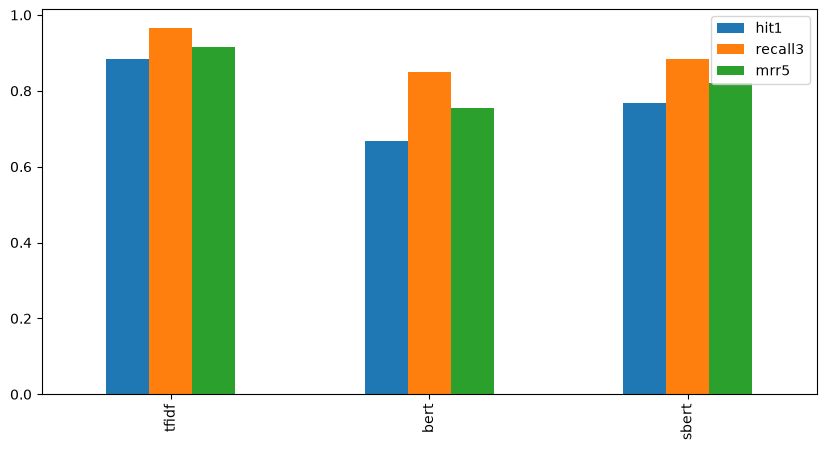

In [52]:
# [학생 구현] CP-08 — Sentence-BERT 검색 + 성능 비교

def search_sbert(query, k=5):
    query = str(query)
    # TODO 8-1. sbert_query_cache에 query가 있으면 캐시를, 없으면 sbert_model.encode()를 사용하세요.
    if query in sbert_query_cache: 
        query_vector = sbert_query_cache[query]
    else:
        query_vector = sbert_model.encode(query) 
        sbert_query_cache[query] = query_vector
    # TODO 8-2. 질문 벡터와 sbert_doc_vectors의 코사인 유사도를 계산하고 top_k_results()로 검색 결과를 반환하세요.
    scores = cosine_scores(query_vector, sbert_doc_vectors)
    
    return top_k_results(scores, corpus_df, k=k)

# TODO 8-3. evaluate_search(search_sbert, valid_df)로 SBERT Validation을 평가하고
#           결과를 sbert_summary, sbert_detail이라는 이름으로 받으세요.
sbert_summary, sbert_detail = evaluate_search(search_sbert, valid_df)
# TODO 8-4. tfidf_summary, bert_summary, sbert_summary를 comparison_df로 만드세요.
#             행: tfidf, bert, sbert / 열: hit1, recall3, mrr5
comparison_df = pd.DataFrame({
    'tfidf' : tfidf_summary,
    'bert': bert_summary, 
    'sbert' : sbert_summary
}).T
# TODO 8-5. comparison_df를 cp08_validation_comparison.csv로 저장하고 막대그래프를 그리세요.
comparison_df.to_csv(TABLES / 'cp08_validation_comparison.csv')
comparison_df.plot(kind='bar',figsize=(10,5))


**비교 결과 검증(공통).** 세 검색기의 검색 결과 형식이 같고 지표가 0~1 사이인지 확인합니다. 성능의 순위는 데이터에 따라 달라지므로 BERT나 Sentence-BERT가 무조건 높아야 한다는 조건은 없습니다.


In [23]:
# [공통 검증] CP-08
assert comparison_df.index.tolist() == ['tfidf', 'bert', 'sbert']
assert (comparison_df[['hit1', 'recall3', 'mrr5']] >= 0).all().all()
assert (comparison_df[['hit1', 'recall3', 'mrr5']] <= 1).all().all()
assert len(sbert_detail) == len(valid_df)
assert search_sbert(valid_df.iloc[0]['question'], 3)[0]['rank'] == 1
print('CP-08 통과: 세 검색 방식의 Validation 평가 완료')


CP-08 통과: 세 검색 방식의 Validation 평가 완료


**[기록] 결과 해석 — CP-08**

- 세 검색기의 Hit@1·Recall@3·MRR@5 차이: **TF-IDF는 hit1 0.83, recall3 0.96, mrr5 0.91로 세 지표 모두 가장 높은 점수를 기록했다. 특히 recall3가 0.96으로, 전체 질문 중 약 96%에서 정답 문서를 상위 3개 안에 포함했다. 또한 hit1도 0.83으로 가장 높아 정답 문서를 첫 번째로 찾아내는 성능이 가장 좋았으며, mrr5 역시 가장 높아 정답 문서가 전반적으로 높은 순위에 위치했다. 반면 BERT는 recall3가 0.85로 가장 낮았다.**
- 예상과 다른 결과가 있다면 가능 원인: **BERT와 SBERT 가 문맥과 의미적 유사도를 비교하여 학습하는 모델로 더 성능이 높을 줄 알았으나 이번 미니 프로젝트에서는 TF-IDF의 성능이 더 높게 나왔다. 원인은 데이터에 포함된 문서와 질문에서 겹치는 구간이 낮더라도 다른 문서보다 질문과 더 많이 일치한다면 정답을 찾을 수 있다. 이로 인하여 모델의 성능도 중요하지만 다른 문서와의 구분도 중요하다는 걸 알 수 있다.**

**[CP-08 완료 기준]** 세 방식의 동일 Validation 질문 비교표·그래프와 결과 해석을 완성합니다.


---
## CP-09. 검색 실패 사례 분석 및 최종 검색 방식 선정

성능 지표가 비슷하더라도 어떤 질문을 잘 찾고, 어떤 질문에서 실패하는지는 다를 수 있습니다. CP-01에서 세운 가설을 실제 Validation 검색 오류와 비교한 뒤 활용 목적에 맞는 검색 방식을 직접 선택합니다.


**검색 실패 질의 분석(학생 구현).** 세 검색기의 질문별 Hit@1을 합쳐 실패한 질문을 5개 이상 선정합니다. 세 검색기의 상위 문서와 정답 문서 ID를 나란히 비교하고 오류 원인을 기록합니다.


In [24]:
# [학생 구현] CP-09 — 질문별 성공/실패 비교 및 대표 오류 선택
error_df = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
# TODO 9-1. tfidf_detail, bert_detail, sbert_detail을 query_id로 병합하세요.
#             각 모델의 hit1/recall3/rank에는 모델 이름 접두사를 붙이세요.
# TF-IDF 컬럼 이름 변경
tfidf = tfidf_detail.rename(columns={
    'hit1': 'tfidf_hit1',
    'recall3': 'tfidf_recall3',
    'rank': 'tfidf_rank'
})

# BERT 컬럼 이름 변경
bert = bert_detail.rename(columns={
    'hit1': 'bert_hit1',
    'recall3': 'bert_recall3',
    'rank': 'bert_rank'
})

# SBERT 컬럼 이름 변경
sbert = sbert_detail.rename(columns={
    'hit1': 'sbert_hit1',
    'recall3': 'sbert_recall3',
    'rank': 'sbert_rank'
})

# 병합
error_df = error_df.merge(tfidf[['query_id', 'tfidf_hit1', 'tfidf_recall3', 'tfidf_rank']], on='query_id')
error_df = error_df.merge(bert[['query_id', 'bert_hit1', 'bert_recall3', 'bert_rank']], on='query_id')
error_df = error_df.merge(sbert[['query_id', 'sbert_hit1', 'sbert_recall3', 'sbert_rank']], on='query_id')
# TODO 9-2. num_top1_failures = 3 - 세 모델의 hit1 합계를 계산하세요.
num_top1_failures = 3 - (
    error_df['tfidf_hit1'] +
    error_df['bert_hit1'] + 
    error_df['sbert_hit1']
)
# TODO 9-3. 실패가 많은 질문 상위 5개를 error_cases로 추출해 표로 출력하세dis요.
error_cases = error_df.iloc[
    num_top1_failures.argsort()[::-1][:5]
]
display(error_cases)
# TODO 9-4. 질문 하나에 대한 세 검색기의 Top-3 doc_id·유사도를 출력하세요.
#question = valid_df.iloc[46]['question']
question = error_cases.iloc[0]['question']
tfidf_top3 = search_tfidf(question, k=3)
bert_top3 = search_bert(question, k=3)
sbert_top3 = search_sbert(question, k=3)

print('TF-IDF 결과',tfidf_top3)
print('BERT 결과\n',bert_top3)
print('SBERT 결과\n',sbert_top3)
# TODO 9-5. error_cases를 TABLES/'cp09_error_cases.csv'에 저장하세요.
# [힌트] CP-01의 valid_overlap[['query_id', 'overlap']]을 query_id로 병합해 두면
#        실패한 질문의 겹침 비율을 함께 볼 수 있습니다.
error_cases = error_cases.merge(
    valid_overlap[['query_id', 'overlap']],
    on='query_id'
)
error_cases.to_csv(TABLES/'cp09_error_cases.csv')

,query_id,question,relevant_doc_id,tfidf_hit1,tfidf_recall3,tfidf_rank,bert_hit1,bert_recall3,bert_rank,sbert_hit1,sbert_recall3,sbert_rank
46,QV047,자바 API를 개발한 회사는 어디인가?,D048,0,0,NaN,0,0,NaN,0,0,4.0
19,QV020,소넨이 상을 받았던 해는?,D138,0,0,NaN,0,0,NaN,0,0,NaN
45,QV046,싸움에 대비한 체육을 다룬 교육의 명칭은?,D080,1,1,1.0,0,1,3.0,0,1,2.0
54,QV055,맛소금을 만드는 회사는?,D034,1,1,1.0,0,0,4.0,0,1,3.0
32,QV033,로봇을 만들 수 있는 부스를 운영한 기관은?,D152,1,1,1.0,0,1,2.0,0,0,NaN


TF-IDF 결과 [{'rank': 1, 'doc_id': 'D013', 'score': 0.10814532589105469, 'text': '한국신용데이터(KCD)는 소비자에게 카드 사용 마이데이터를 바탕으로 맞춤형 동네 맛집 정보를 제공하는 서비스 ‘페이노트’ 스마트폰 앱을 출시했다고 9일 밝혔다. 페이노트는 카드사 ‘마이데이터’ API를 기반으로 개발한 서비스다. 소비자의 카드 결제 데이터를 API 방식으로 카드사로부터 전달 받아 개인의 소비 패턴에 맞는 지역 정보를 제공한다. 예컨대, 서울 강남역 인근 지역에서 점심 식사를 하는 직장인이라면, 과거 지출 내역에 맞춰 강남역 인근의 식당, 카페, 술집의 할인 쿠폰을 받아볼 수 있다. 이번에 안드로이드 앱을 먼저 출시했으며, 아이폰 앱은 3분기 중 출시 예정이다. 앱 없이도 카카오톡 플러스친구 형태로 서비스를 사용할 수 있다. 현재는 신한카드, 현대카드, BC카드를 쓰는 사용자에게 맞춤형 정보를 제공하고 있다. 페이노트는 한국신용데이터의 경영관리 서비스 캐시노트를 사용하는 전국 65만여 사업장의 정보를 바탕으로 지역 맛집 정보를 제공한다. 페이노트와 유사한 동네 맛집 정'}, {'rank': 2, 'doc_id': 'D137', 'score': 0.08531652028037214, 'text': '“덱스터에 대한 투자는 시작일 뿐입니다. 내년부터 한국 엔터테인먼트·콘텐츠 회사 인수에 본격적으로 나설 예정입니다.”22일 열린 영화 시각기술(VFX) 전문업체 덱스터의 코스닥 상장 기념식에 참석한 왕쓰충 완다그룹 이사(27·사진)는 “한국 회사 인수합병(M&A)을 위해 아예 서울에 지낼 집을 마련하기로 했다”며 이같이 말했다.왕 이사는 중국 최대 민영 재벌 그룹인 완다그룹 왕젠린(王健林) 회장의 아들이다. 완다그룹 계열 투자회사인 프로메테우스캐피털(베이징푸쓰투자유한공사) 대표를 맡고 있다. 올해 게임 생중계 서비스인 판다TV와 엔터테인먼트 회사 바나나플랜을 설립하는 등 엔터·콘텐츠업계에 활발한 투자를 벌이고 있다

In [25]:
print('전체 평균 겹침 비율')
print(valid_overlap['overlap'].mean())

print('실패 질문 평균 겹침 비율')
print(error_cases['overlap'].mean())

전체 평균 겹침 비율
0.47400094682728616
실패 질문 평균 겹침 비율
0.35844155844155845


**[기록] 결과 해석 — CP-09**

- 대표 실패 질문 5개에서 확인한 원인 (표면 단어 불일치, 문서 길이, 의미 혼동 등): **대표 실패 질문 5개는 연도와 회사명, 기관명 등 구체적인 사실을 물어보는 질문이 많았다. 질문에 사용된 단어와 문서에 사용된 단어가 다르거나 의미가 비슷한 표현을 정답으로 잘못 판단했을 가능성이 있다.**
- 실패한 질문의 겹침 비율(CP-01)은 전체 평균과 비교해 어떤가? 겹침이 낮은 질문은 어느 검색기가 더 잘 찾았는가?: **실패 질문 5개의 평균 겹침 비율은 약 0.36으로 전체 질문의 평균인 약 0.47보다 약 0.12 낮았다. 겹침 비율이 가장 낮은 QV046(약 0.17)에서는 TF-IDF가 정답 문서를 1위로 검색해 가장 좋은 성능을 보였다. 또한 QV033에서도 TF-IDF가 1위를 기록했다. 따라서 겹침 비율이 낮더라도 TF-IDF가 정답을 정확하게 찾는 경우가 있음을 확인했다.**
- CP-01에서 예상한 TF-IDF/BERT의 장단점이 실제로 확인되었는가?: **TF-IDF는 단어의 표면적인 일치 여부를 중심으로 검색하기 때문에 단어 겹침이 높은 질문에서 유리할 것으로 예상했다. BERT는 문맥과 의미를 파악하므로 표현이 다르더라도 의미가 유사한 문서를 찾는 데 장점이 있을 것으로 예상했다. 하지만 실제 결과에서는 겹침 비율이 낮은 질문에서도 TF-IDF가 정답을 1위로 검색하는 경우가 있었으며, BERT도 일부 질문에서 정답을 찾지 못했다. 따라서 예상한 모델별 장단점이 모든 질문에서 동일하게 나타나지는 않았다.**
- 어떤 질문 유형에서 최종 검색기가 특히 좋은/나쁜 결과를 보이는가?: **이번 프로젝트 데이터에서는 TF-IDF가 전반적으로 가장 좋은 성능을 보였다. 특히 질문에 포함된 핵심 단어와 문서의 표현이 일치하는 경우 정답 문서를 높은 순위로 검색하는 경향을 보였다. 반면 특정 회사명, 기관명, 연도 등 구체적인 사실을 묻는 일부 질문에서는 세 검색기 모두 정답을 찾지 못하는 경우가 있었다. 이를 통해 질문에 포함된 단어뿐 아니라 문서에서 해당 사실을 어떤 표현으로 설명하는지도 검색 성능에 영향을 줄 수 있음을 확인했다.**

**최종 검색 방식 선정(학생 구현).** 실제 활용 목적과 가장 중요한 검색 지표를 정의한 후 Validation 결과에 근거해 검색 방식을 선택합니다. 선택값·대안·트레이드오프를 JSON으로 저장하면 최종 ADR의 근거로 활용할 수 있습니다.


In [51]:
# [학생 구현] CP-09 — 사용 목적 및 선택 근거
# TODO 9-6. 검색기를 사용할 실제 상황을 USE_CASE로 한 문장 작성하세요.
USE_CASE = "사용자가 질문을 입력하여 관련 문서에서 답변에 필요한 정보를 찾는 문서 검색 서비스"
# TODO 9-7. PRIORITY_METRIC을 'hit1', 'recall3', 'mrr5' 중 하나로 지정하세요.
PRIORITY_METRIC = 'hit1'
# TODO 9-8. comparison_df의 Validation 점수와 오류 사례를 고려하여
#             SELECTED_METHOD를 'tfidf', 'bert', 'sbert' 중 하나로 직접 선택하세요.
SELECTED_METHOD = 'tfidf'
# TODO 9-9. SELECTION_REASON에 실제 수치와 다른 방법의 장단점을 2~3문장으로 적으세요.
# raise NotImplementedError('CP-09 최종 검색 방식·판단 근거를 지정하세요.')
SELECTION_REASON = "TF-IDF 모델을 최종 선택하였다. 정답문서가 첫번째로 나오는 지표인 hit을 봤을 때 0.883으로 가장 높은 성능을 보였으며 외에도 질문에 대한 정답문서가 첫번째부터 세번째 안에 포함되는지 나타내는 recall이 0.967으로 가장 정확하였다. TF-IDF가 세 평가 지표에서 모두 높은 성능을 보였으며 BERT는 문맥을 파악하고 의미적 유사성을 파악하는 장점이 있었지만 비교적 성능이 낮게 나왔다"
assert PRIORITY_METRIC in ('hit1', 'recall3', 'mrr5')
assert SELECTED_METHOD in ('tfidf', 'bert', 'sbert')
selection = {'use_case': USE_CASE, 'priority_metric': PRIORITY_METRIC,
             'selected_method': SELECTED_METHOD, 'selection_reason': SELECTION_REASON,
             'validation_metrics': comparison_df.reset_index().to_dict('records')}
(REPORTS / 'cp09_selection.json').write_text(
    json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('선정 모델:', SELECTED_METHOD, '| 우선 지표:', PRIORITY_METRIC)


선정 모델: tfidf | 우선 지표: hit1


**[CP-09 완료 기준]** 검색 실패 질문 5건을 분석하고, CP-01의 가설을 검증합니다. 사용 목적·우선 지표·선택 검색기·근거를 기록한 `cp09_selection.json`을 저장합니다.


---
## CP-10. 최종 `search_docs()` 완성 및 보류 Test 검증

CP-09에서 선택한 검색 방식을 하나의 사용자 함수 `search_docs()`로 연결합니다. **선택한 방법은 Test 결과를 확인한 뒤 바꾸지 않으며**, 새로운 질문에서도 최종 검색기가 동작하는지 확인합니다.


**최종 검색 함수(학생 구현).** 저장된 선택값에 맞춰 TF-IDF/BERT/Sentence-BERT 함수를 호출하고 Top-k 문서를 반환합니다. 이후 처음으로 Test 질문을 읽어 별도 데이터에서의 최종 성능을 검증합니다.


In [32]:
#for method in ['tfidf', 'bert', 'sbert']:
#    result = search_docs("테스트 질문", method=method)
#    print(method, result[0].keys())

tfidf dict_keys(['rank', 'doc_id', 'score', 'text'])
bert dict_keys(['rank', 'doc_id', 'score', 'text'])
sbert dict_keys(['rank', 'doc_id', 'score', 'text'])


In [42]:
# [학생 구현] CP-10 — 최종 검색기 인터페이스

def search_docs(query, k=3, method=SELECTED_METHOD):
    """선택한 검색 방식의 상위 k개 문서 반환."""
    # TODO 10-1. method가 'tfidf'라면 search_tfidf(), 'bert'라면 search_bert(),
    #              'sbert'라면 search_sbert()를 호출하도록 작성하세요.
    # TODO 10-2. 세 방법 모두 동일한 rank/doc_id/score/text 구조로 반환하세요.
    if method == 'tfidf' :
        return search_tfidf(query, k=k)
    elif method == 'bert':
        return search_bert(query, k=k)
    elif method == 'sbert':
        return search_sbert(query, k=k)
    
# TODO 10-3. 본인이 만든 새로운 질문 한 개로 search_docs() Top-3를 확인하세요.
new_question = "지능형 교통시스템 관련 문서"

top3 = search_docs(new_question, k=3)
display(pd.DataFrame(top3))

,rank,doc_id,score,text
0,1,D190,0.115368,도로에 지능형 교통시스템을 구축하고 모든 학교에 초당 1기가비트(Gbps) 속도의 ...
1,2,D092,0.061679,"장에 공급할 예정""이라며, “많은 자동차 모델에 확장이 가능하고 기능적으로 안전한 ..."
2,3,D172,0.041055,", 징동, 핀둬둬의 판매자, 미국 아마존, 월마트 이커머스의 판매자, 일본 큐텐, ..."


**보류 Test 평가·저장(학생 구현).** CP-09의 선택을 고정한 채 Test 질문 20개를 처음으로 평가합니다. Validation과 Test의 성능 차이 및 데이터 한계를 기록하고 CSV·JSON 결과를 출력합니다.


In [49]:
# [학생 구현] CP-10 — 보류 Test 최종 평가 (이 셀에서 Test 정답을 처음 사용)
test_df = pd.read_csv(TEST_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(test_df) == 20
# TODO 10-4. SELECTED_METHOD를 바꾸지 않고 search_docs()로 Test 질문 20개를 평가하고
#            결과를 test_summary, test_detail이라는 이름으로 받으세요.
test_summary, test_detail = evaluate_search(
    search_docs,
    test_df
)
# TODO 10-5. comparison_df의 선택 모델 Validation 점수와 Test 점수를 final_compare라는 DataFrame으로
#            정리하세요. 행은 Validation, Test 두 개입니다.
validation_result = comparison_df.loc[SELECTED_METHOD]

final_compare = pd.DataFrame(
    [validation_result, pd.Series(test_summary)],
    index = ['Validation', 'Test']
)

display(final_compare)
# TODO 10-6. final_compare는 TABLES / 'cp10_validation_test_comparison.csv'로,
#            test_detail은 TABLES / 'cp10_test_query_results.csv'로 저장하세요.
final_compare.to_csv(TABLES / 'cp10_validation_test_comparison.csv',
                    index=True
)
test_detail.to_csv(TABLES / 'cp10_test_query_results.csv')
# TODO 10-7. 선택 방법, 우선 지표, Validation·Test 점수를 REPORTS / 'cp10_final_report.json'에 저장하세요.
# [주의] 검증 셀이 위 변수 이름과 파일 이름을 그대로 확인합니다.
final_report = {
    'selected_method': SELECTED_METHOD,
    'priority_metric': PRIORITY_METRIC,
    'validation_scores': final_compare.loc['Validation'].to_dict(),
    'test_scores': final_compare.loc['Test'].to_dict()
}

(REPORTS / 'cp10_final_report.json').write_text(
    json.dumps(final_report, ensure_ascii=False, indent=2),
    encoding='utf-8'
)


,hit1,recall3,mrr5
Validation,0.883333,0.966667,0.916667
Test,0.800000,0.800000,0.812500


269

**최종 프로젝트 검증(공통).** Test 데이터는 더 이상 모델 선택에 사용하지 않습니다. 두 분할의 성능표와 JSON을 저장했는지 확인하고, 최종 검색 함수가 사용자가 입력한 질문에서 정상 동작하는지 점검합니다.


In [ ]:
failed_test = test_detail[test_detail['recall3'] == 0]

display(failed_test)

In [50]:
# [공통 검증] CP-10
assert len(test_detail) == 20
assert len(final_compare) == 2
assert all((TABLES / n).is_file() for n in ['cp10_validation_test_comparison.csv', 'cp10_test_query_results.csv'])
assert (REPORTS / 'cp10_final_report.json').is_file()
assert search_docs('이 기사에서 설명하는 현상은 무엇인가요?', 3)[0]['rank'] == 1
print('CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료')


CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료


**[기록] 결과 해석 — CP-10**

- 최종 선택 모델의 Validation 및 Test 지표 차이: **최종 선택한 TF-IDF 모델은 Hit 0.883, recall 0.966, Mrr 0.9167로 검증 점수에서보다 테스트 점수 0.8/0.8/0.812 순서로 소폭 낮아졌다. 테스트 점수는 낮아졌지만 질문 20개 중에서 4개 질문에서 1위 검색을 실패하였다.**
- 검색에 실패한 Test 질문의 특징과 예상 원인: **인물과 같은 구체적인 사실을 묻는 질문과 단순한 오타나 문맥을 파악해야 되는 질문('ㅋ')에서 어려움이 있었을 것으로 예상된다. Tf-IDF는 문맥과의 관계보다는 단어의 일치 여부를 중심으로 검색하기 때문이다.**
- 이 작은 KLUE-MRC 변환 데이터로 실제 업무 검색 품질을 보장할 수 없는 이유: **이번 미니프로젝트에서 사용한 데이터는 실제 업무보다 규모가 작고 제한적이기 때문에 실제 업무에서 사용하는 다양한 질문을 반영하기 어렵다. 이번 평가 결과만으로는 실제 업무 환경에서의 동일한 성능을 보장할 수 없으며 다양한 데이터와 실제 업무에서의 추가 검증이 필요하다.**

### CP-10 종료 후 — 프로젝트 문서 작성 (별도 제출, 체크포인트에 포함되지 않음)

1. **프로젝트 명세서:** 입력·출력, 데이터셋, 세 검색기의 역할과 주요 함수
2. **ADR:** USE_CASE, PRIORITY_METRIC, SELECTED_METHOD, SELECTION_REASON 및 비교한 대안
3. **결과 분석 문서:** CP-01 가설, CP-08 비교표, CP-09 실패 사례, CP-10 Test 평가·한계

**[최종 완료 기준]** CP-01~10 구현·검증, 선택 근거 기록, 보류 Test 평가, 필수 문서 작성 후 Notebook을 GitHub에 Push합니다. 다운로드한 원본 문서·대형 모델 가중치는 GitHub에 올리지 않습니다.
